# Week 3: building the activity index and testing it honestly

**Five-line findings.** 7 indicators, every model fitted only on earlier months. Main test: IIP base 2022-23 (41 complete months, 29 scored). Long test: old IIP base 2011-12, Apr 2019 to Mar 2026.

1. **More history overturned the first result.** With only 29 months the small regression looked 2% better than the baseline and diesel looked robust (r = 0.48). On 41 months, **no index version beats the 12-month-average baseline**: MAE 1.88 for the baseline against 1.98 (z-score, -5.3%), 2.07 (PCA, -10.2%) and 2.32 (regression, -23.6%). Diesel's correlation fell to 0.17.
2. **Over 2019 to 2026 the index does beat the baseline** (66 scored months, COVID months excluded): the regression by +18.4% and the z-score index without UPI by +20.8%, calling direction right in 69% of months. Fuel and GST track IIP closely over that span: diesel r = 0.85, petrol 0.86, gross GST 0.84, and still 0.83, 0.71, 0.64 without the COVID months.
3. **But the edge disappears in calm conditions.** Score the same long-sample models only from Apr 2022 and all are worse than the baseline (-15.6% to -6.3%); only from Apr 2023, worse still (-16.5% to -26.8%). The index detects big swings, such as the 2020 to 2022 rebound, not small month-to-month moves.
4. **UPI carries no signal.** Its growth correlates 0.11 (volume) and 0.09 (value) with IIP over 2019 to 2026, because it measures adoption, not activity. Dropping it improves the z-score index from -6.2% to +20.8%. Lags: strongest at lag 0; GST published a month after an IIP month correlates 0.32 with it (new base) but arrives too late to forecast with.
5. **What this means.** Present the index as an early-read signal for large changes in activity, not a more precise forecaster in a calm period. October 2026 is a calm month and a Diwali-shift month, so the forecast will be published next to the 12-month-average baseline, with an interval from these backtest errors, and the success rule will say so.


In [1]:
import sys
sys.path.insert(0, "../src/analysis")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import pulse
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
BLUE, ORANGE, GREY = "#2a5db0", "#d9822b", "#8a8f98"

## 1. Monthly panel
Year-on-year (YoY) growth, not levels: it removes seasonality and trend, makes indicators comparable and avoids a spurious correlation between two rising series. Target: MoSPI IIP growth. The panel comes from the `v_growth_monthly` view in SQL. Two IIP series exist and are never spliced (their growth correlates only 0.40 over 36 overlapping months): base 2022-23 (main, Apr 2023 onward) and base 2011-12 (long, ends Mar 2026).

In [2]:
panel = pulse.load_panel()                                   # IIP base 2022-23
sample = pulse.complete_rows(panel, pulse.CORE)
long_panel = pulse.load_panel("2011-12", start=pulse.LONG_START)  # IIP base 2011-12 from Apr 2019
long_sample = pulse.complete_rows(long_panel, pulse.CORE_LONG)
print(f"main sample:  {len(sample)} complete months, {sample.index.min():%Y-%m} to {sample.index.max():%Y-%m}")
print(f"long sample:  {len(long_sample)} complete months, {long_sample.index.min():%Y-%m} to {long_sample.index.max():%Y-%m}; COVID-affected months inside: {int(long_sample.covid_affected.sum())}")
panel.loc["2026-03-01":, pulse.CORE + ["iip"]].round(1)

main sample:  41 complete months, 2023-04 to 2026-08
long sample:  83 complete months, 2019-04 to 2026-03; COVID-affected months inside: 5


,upi_daily_volume_mn,upi_value_cr,gst_net_ex_cess_cr,fuel_diesel_kt,fuel_bitumen_kt,fuel_atf_kt,fuel_petrol_kt,iip
month,,,,,,,,
2026-03-01,23.7,19.2,8.2,8.1,-18.9,0.7,7.6,3.0
2026-04-01,24.9,21.2,7.3,0.8,-52.2,-0.1,6.8,4.9
2026-05-01,24.2,18.9,3.4,1.6,-52.1,1.0,3.4,5.0
2026-06-01,23.5,20.3,11.2,6.1,-35.2,-0.1,7.4,8.8
2026-07-01,21.5,19.1,15.8,10.0,9.4,-0.6,9.2,7.4
2026-08-01,22.5,20.0,8.3,6.8,19.7,2.3,8.2,8.0
2026-09-01,22.6,18.0,NaN,5.6,17.2,0.9,8.0,NaN


**Why gross GST in the long sample:** refund data (so net GST) only exists from Apr 2020, so the long sample uses gross GST excluding cess. **Why Apr 2019:** GST began in Jul 2017 with near-empty first months, so growth is only reliable once the base year (Apr 2018) is normal.

**COVID months:** Apr-Jun 2020 (the plan's flag) plus Apr-Jun 2021, whose YoY is a base effect, are called COVID-affected and removed in the 'COVID excluded' runs.

In [3]:
shift = panel.index[panel["diwali_shift"].fillna(False).astype(bool)]
print("Diwali-shift months since 2023:", [m.strftime("%Y-%m") for m in shift if m >= pd.Timestamp("2023-01-01")])

Diwali-shift months since 2023: ['2023-10', '2023-11', '2024-10', '2024-11']


**Heads-up for the October forecast:** Diwali was on 20 Oct 2025 and falls on 8 Nov 2026, so **October 2026 is a Diwali-shift month**: its YoY comparison is against a festive October.

## 2. Baselines (fixed before any model)
Two naive forecasts of the next month's IIP growth: last month's value, and the average of the last 12 months. Yardstick: mean absolute error (MAE) in percentage points over a rolling test. The index has to beat these.

## 3. Lag tests
Correlation of indicator growth at *t-k* with IIP growth at *t*. `-1` means the indicator one month **after** the IIP month, which a forecaster does not have yet. First the main sample (IIP base 2022-23).

In [4]:
lags = pd.read_csv("../docs/results/lag_tests.csv")
main = lags[(~lags.exclude_covid) & (lags.start_shift_months == 0)]
tab = main.pivot(index="indicator", columns="lag_months", values="corr").round(2)
tab["n_months (lag 0)"] = main[main.lag_months == 0].set_index("indicator")["n_months"]
tab

lag_months,-1,0,1,2,n_months (lag 0)
indicator,,,,,
fuel_atf_kt,0.18,0.06,0.03,-0.13,41
fuel_bitumen_kt,-0.08,0.11,-0.13,-0.23,41
fuel_diesel_kt,-0.03,0.17,-0.13,-0.18,41
fuel_petrol_kt,0.57,0.05,-0.00,0.04,41
gst_net_ex_cess_cr,0.32,0.29,0.07,0.09,41
upi_daily_volume_mn,0.11,0.19,0.14,0.08,41
upi_value_cr,0.17,0.24,0.24,0.20,41


Now the long sample (IIP base 2011-12, Apr 2019 to Mar 2026), with and without the COVID-affected months.

In [5]:
lago = pd.read_csv("../docs/results/lag_tests_old_base.csv")
a = lago[(lago.lag_months == 0) & (lago.start_shift_months == 0)]
out = a.pivot(index="indicator", columns="exclude_covid", values="corr").round(2)
out.columns = ["with COVID months", "COVID months excluded"]
out["n_months (all)"] = a[~a.exclude_covid].set_index("indicator")["n_months"]
out

,with COVID months,COVID months excluded,n_months (all)
indicator,,,
fuel_atf_kt,0.67,0.52,83
fuel_bitumen_kt,0.48,0.46,83
fuel_diesel_kt,0.85,0.83,83
fuel_petrol_kt,0.86,0.71,83
gst_gross_ex_cess_cr,0.84,0.64,83
upi_daily_volume_mn,0.11,0.00,83
upi_value_cr,0.09,-0.06,83


In [6]:
x = lago[(~lago.exclude_covid) & (lago.start_shift_months == 0)].pivot(index="indicator", columns="lag_months", values="corr").round(2)
x.columns = [f"lag {c}" for c in x.columns]
x

,lag -1,lag 0,lag 1,lag 2
indicator,,,,
fuel_atf_kt,0.49,0.67,0.43,0.21
fuel_bitumen_kt,0.20,0.48,0.38,0.19
fuel_diesel_kt,0.54,0.85,0.58,0.34
fuel_petrol_kt,0.54,0.86,0.56,0.29
gst_gross_ex_cess_cr,0.46,0.84,0.46,0.25
upi_daily_volume_mn,0.06,0.11,0.08,-0.01
upi_value_cr,0.06,0.09,0.08,-0.01


**Sensitivity to the sample start date** (lag 0, COVID excluded): the first month moved later by 0, 3 and 6 months.

In [7]:
sh = lago[(lago.exclude_covid) & (lago.lag_months == 0)].pivot(index="indicator", columns="start_shift_months", values="corr").round(2)
sh.columns = [f"start +{c} months" for c in sh.columns]
sh

,start +0 months,start +3 months,start +6 months
indicator,,,
fuel_atf_kt,0.52,0.52,0.52
fuel_bitumen_kt,0.46,0.46,0.46
fuel_diesel_kt,0.83,0.83,0.83
fuel_petrol_kt,0.71,0.71,0.73
gst_gross_ex_cess_cr,0.64,0.64,0.63
upi_daily_volume_mn,0.00,0.02,0.11
upi_value_cr,-0.06,-0.08,-0.01


The long-sample correlations for fuel and GST are large and stable. They are driven by the big swings of 2020 to 2022. Restricting the period shows how much:

In [8]:
p = long_panel[~long_panel.covid_affected.astype(bool)]
rows = []
for label, lo in [("Apr 2019 - Mar 2026", None), ("Apr 2022 - Mar 2026", "2022-04-01"), ("Apr 2023 - Mar 2026 (calm)", "2023-04-01")]:
    q = p if lo is None else p[p.index >= lo]
    q = q[pulse.CORE_LONG + ["iip"]].dropna()
    rows.append({"period": label, "months": len(q), "IIP std (pts)": round(q.iip.std(), 1),
                 **{k.split("_")[0] + "_" + k.split("_")[1]: round(q[k].corr(q.iip), 2) for k in pulse.CORE_LONG}})
pd.DataFrame(rows).set_index("period")

,months,IIP std (pts),upi_daily,upi_value,gst_gross,fuel_diesel,fuel_bitumen,fuel_atf,fuel_petrol
period,,,,,,,,,
Apr 2019 - Mar 2026,78,5.6,0.01,-0.06,0.64,0.83,0.46,0.52,0.71
Apr 2022 - Mar 2026,48,3.6,0.42,0.42,0.41,0.63,0.50,0.45,0.56
Apr 2023 - Mar 2026 (calm),36,2.4,0.39,0.38,-0.06,0.54,0.69,0.32,-0.23


## 4. The index
Three versions, simplest first: (a) equal-weight average of standardised growth, (b) first principal component, (c) a small ridge regression on the two indicators most correlated with IIP *in the training months*. In every backtest, standardisation, PCA loadings, indicator selection and regression weights are fitted on earlier months only.

In [9]:
idx = pulse.full_sample_indices(panel, pulse.CORE)
print(f"First principal component explains {idx.attrs['pca_explained_variance']:.0%} of the variance.")
idx.attrs["pca_weights"].round(2).rename("PCA weight").to_frame()

First principal component explains 46% of the variance.


,PCA weight
upi_daily_volume_mn,0.53
upi_value_cr,0.53
gst_net_ex_cess_cr,0.33
fuel_diesel_kt,0.08
fuel_bitumen_kt,0.26
fuel_atf_kt,0.50
fuel_petrol_kt,0.02


UPI carries the largest weights even though it has the weakest link to IIP over the long sample. Another reason the PCA index is hard to defend.

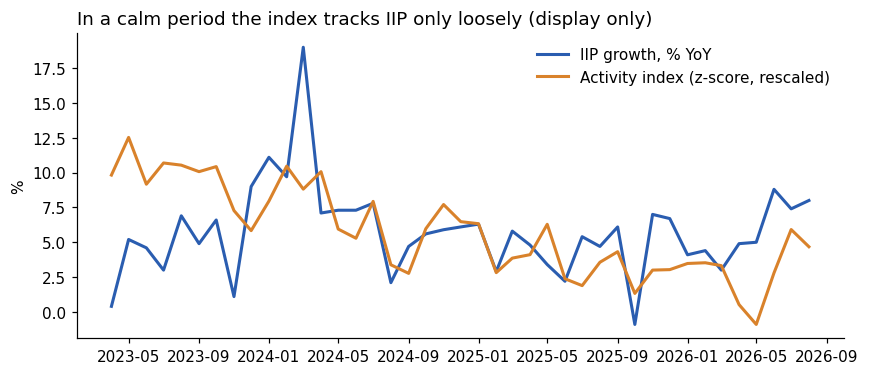

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(sample.index, sample["iip"], color=BLUE, lw=2, label="IIP growth, % YoY")
z = idx["zscore_index"]
scaled = (z - z.mean()) / z.std() * sample["iip"].std() + sample["iip"].mean()
ax.plot(sample.index, scaled, color=ORANGE, lw=2, label="Activity index (z-score, rescaled)")
ax.set_title("In a calm period the index tracks IIP only loosely (display only)", loc="left")
ax.legend(frameon=False); ax.set_ylabel("%"); plt.show()

## 5. Rolling-origin backtest, main sample
For each month: fit only on earlier months, forecast that month, move forward. Minimum training window 12 months. IIP base 2022-23.

In [11]:
res = pulse.rolling_origin(panel, pulse.CORE)
summary = pulse.summarise(res)
ref = pulse.momentum_hit_rate(panel, pd.DatetimeIndex(res["month"].unique()))
print(f"Out-of-sample months: {res['month'].nunique()} ({res['month'].min():%Y-%m} to {res['month'].max():%Y-%m})")
print(f"Reference: repeating last month's direction gets {ref:.0f}% (IIP growth tends to reverse).")
summary

Out-of-sample months: 29 (2024-04 to 2026-08)
Reference: repeating last month's direction gets 33% (IIP growth tends to reverse).


,n_months,mae,rmse,direction_hit_pct,mae_improvement_vs_best_baseline_pct
model,,,,,
naive_last,29,2.241,3.523,NaN,-19.193
naive_mean12,29,1.880,2.498,71.429,0.000
zscore_index,29,1.979,2.685,75.000,-5.258
pca_index,29,2.072,2.822,75.000,-10.175
regression,29,2.324,2.961,60.714,-23.596


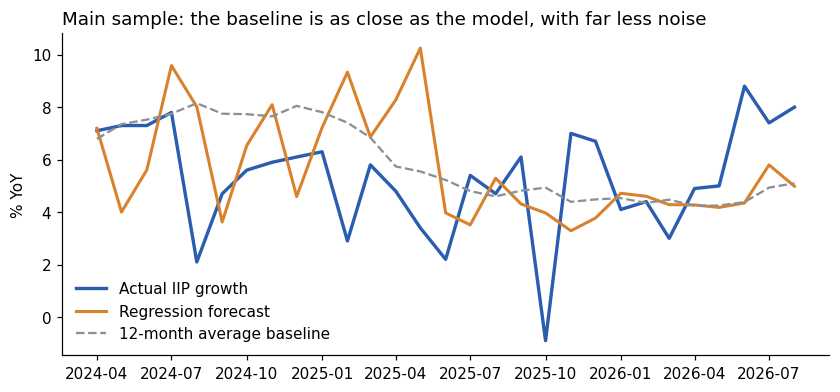

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.8))
a = res[res.model == "regression"].set_index("month")
ax.plot(a.index, a["actual"], color=BLUE, lw=2.2, label="Actual IIP growth")
ax.plot(a.index, a["forecast"], color=ORANGE, lw=2, label="Regression forecast")
ax.plot(res[res.model == "naive_mean12"].set_index("month")["forecast"], color=GREY, lw=1.5, ls="--", label="12-month average baseline")
ax.set_title("Main sample: the baseline is as close as the model, with far less noise", loc="left")
ax.set_ylabel("% YoY"); ax.legend(frameon=False); plt.show()

## 6. Long-sample backtest (IIP base 2011-12, Apr 2019 to Mar 2026)
Same method on the longer history, COVID-affected months removed from training and scoring, UPI left out (it carries no signal over this span).

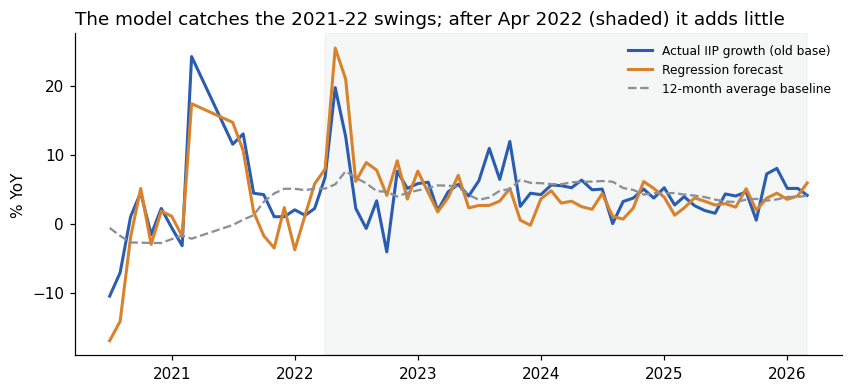

In [13]:
lres = pulse.rolling_origin(long_panel, pulse.NO_UPI, drop_covid=True)
fig, ax = plt.subplots(figsize=(9, 3.8))
a = lres[lres.model == "regression"].set_index("month")
ax.plot(a.index, a["actual"], color=BLUE, lw=2, label="Actual IIP growth (old base)")
ax.plot(a.index, a["forecast"], color=ORANGE, lw=2, label="Regression forecast")
ax.plot(lres[lres.model == "naive_mean12"].set_index("month")["forecast"], color=GREY, lw=1.5, ls="--", label="12-month average baseline")
ax.axvspan(pd.Timestamp("2022-04-01"), a.index.max(), color=GREY, alpha=0.08)
ax.set_title("The model catches the 2021-22 swings; after Apr 2022 (shaded) it adds little", loc="left")
ax.set_ylabel("% YoY"); ax.legend(frameon=False, fontsize=8); plt.show()

In [14]:
rob = pd.read_csv("../docs/results/robustness.csv")
long_rows = rob[rob.variant.str.contains("2011-12")]
t = long_rows.pivot(index="variant", columns="model", values="mae_improvement_vs_best_baseline_pct")[["zscore_index", "pca_index", "regression"]].round(1)
t.join(long_rows.groupby("variant")["n_months"].first())

,zscore_index,pca_index,regression,n_months
variant,,,,
"IIP base 2011-12 (robustness series), COVID months included",-17.9,9.5,18.4,71
"IIP base 2011-12, COVID excluded, without UPI (5 indicators)",20.8,15.8,18.4,66
"IIP base 2011-12, COVID-affected months excluded",-6.2,14.5,18.4,66
"IIP base 2011-12, no UPI, COVID excluded, calm period, scored from Apr 2023",-21.5,-26.8,-16.5,36
"IIP base 2011-12, no UPI, COVID excluded, post-rebound, scored from Apr 2022",-15.6,-20.1,-6.3,48


## 7. Is the result robust? (main sample)
MAE improvement over the better naive baseline, in %, under different reasonable choices.

In [15]:
m = rob[~rob.variant.str.contains("2011-12")]
m.pivot(index="variant", columns="model", values="mae_improvement_vs_best_baseline_pct")[["zscore_index", "pca_index", "regression"]].round(1).join(
    m.groupby("variant")["n_months"].first())

,zscore_index,pca_index,regression,n_months
variant,,,,
8 indicators (adds e-way bills),15.4,-7.8,-24.3,29
excluding Diwali-shift months from scoring,-10.6,-15.6,-26.9,27
"main: 7 indicators, base 2022-23, 12-month minimum training",-5.3,-10.2,-23.6,29
minimum training 10 months,-4.9,-5.8,-18.9,31
minimum training 15 months,7.2,0.4,-17.8,26


## 8. Limits and what happens next
- **Regime dependence.** The index has skill when activity swings widely (2019 to 2022) and none in calm conditions (2023 to 2026), which is what the October 2026 forecast faces.
- **Two IIP series.** The old base (long, ends Mar 2026) and the new base (short, current) correlate only 0.40, so long-sample evidence transfers to the new base with caution.
- **UPI growth reflects adoption** as well as activity and is excluded from the long-sample runs.
- **Provisional data.** Recent GST and fuel figures are revised; the pipeline stores the date each IIP and GDP number was observed.
- **Next (Week 4):** fit the final model on all data, forecast October 2026 IIP growth with an interval from backtest errors, publish it next to the 12-month-average baseline, and write the success rule before the 28 Nov release.